# Лабораторная №1. Математика обучения нейронной сети

**Мотыгуллин Булат Габдулхакович**  
**Группа: Б01-301г**  
**Вариант: 11**

In [1]:
from course import *

seed_all(11)
OUT = ROOT / "results" / "01_math_training"
OUT.mkdir(exist_ok=True, parents=True)

## Задания 1–6. Градиентный спуск и численная производная

Минимизирую L(w) = (w − 3)² с шагами 0.01, 0.1, 0.5, 0.9 и 1.1. Производную проверяю центральной разностью.

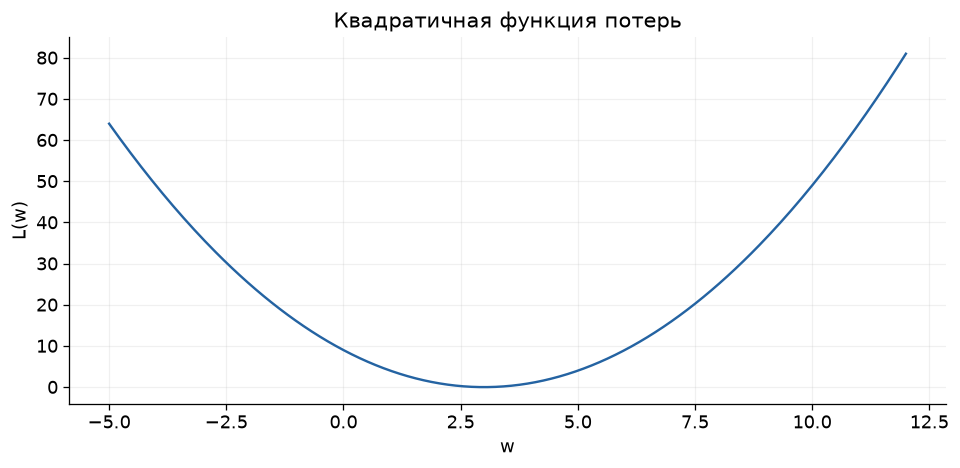

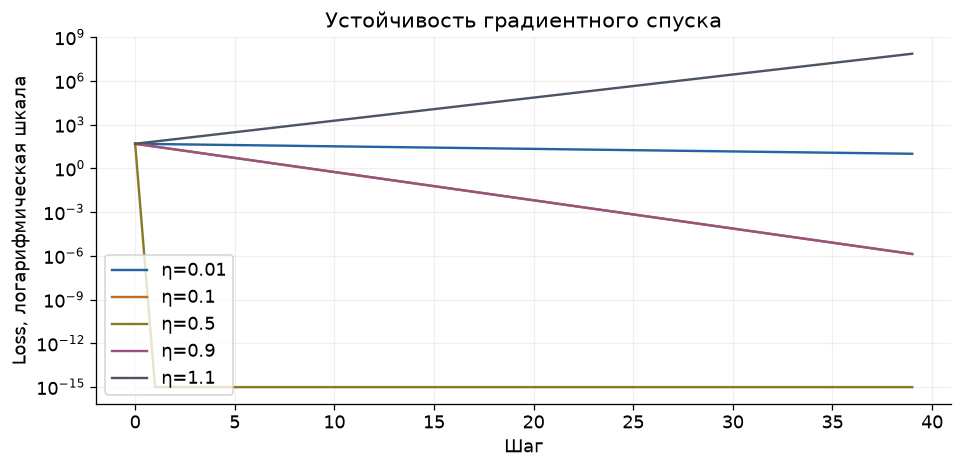

,lr,final_w,final_loss
0,0.01,6.11990,9.733790e+00
1,0.10,3.00093,0.000000e+00
2,0.50,3.00000,0.000000e+00
3,0.90,3.00093,0.000000e+00
4,1.10,10291.40098,1.058512e+08


Аналитическая производная: 4.0 численная: 3.9999999998485687


Для этой квадратичной функции условие устойчивости 0<η<1: ошибка параметра умножается на 1−2η. При η=1.1 наблюдается расходимость.

In [2]:
wgrid = np.linspace(-5, 12, 300)
plt.plot(wgrid, (wgrid - 3) ** 2)
plt.xlabel("w")
plt.ylabel("L(w)")
plt.title("Квадратичная функция потерь")
showfig("loss_function", OUT)
rows = []
for lr in [0.01, 0.1, 0.5, 0.9, 1.1]:
    w = 10.0
    trajectory = []
    for epoch in range(40):
        trajectory.append((w, (w - 3) ** 2))
        w -= lr * 2 * (w - 3)
    a = np.array(trajectory)
    plt.semilogy(np.arange(40), np.maximum(a[:, 1], 1e-15), label=f"η={lr}")
    rows.append({"lr": lr, "final_w": w, "final_loss": (w - 3) ** 2})
plt.xlabel("Шаг")
plt.ylabel("Loss, логарифмическая шкала")
plt.title("Устойчивость градиентного спуска")
plt.legend()
showfig("gd_learning_rates", OUT)
table(rows, OUT)
w = 5.0
eps = 1e-5
numeric = (((w + eps) - 3) ** 2 - ((w - eps) - 3) ** 2) / (2 * eps)
assert np.isclose(numeric, 2 * (w - 3), rtol=1e-6)
print("Аналитическая производная:", 2 * (w - 3), "численная:", numeric)
note(
    "Для этой квадратичной функции условие устойчивости 0<η<1: ошибка параметра умножается на 1−2η. При η=1.1 наблюдается расходимость."
)

## Задания 7–11. Autograd и геометрия

Накопление и очистка градиентов, функция двух переменных, направление −∇L.

Накопление: 14.0 → 28.0
Autograd, итоговый w: 3.0086655616760254


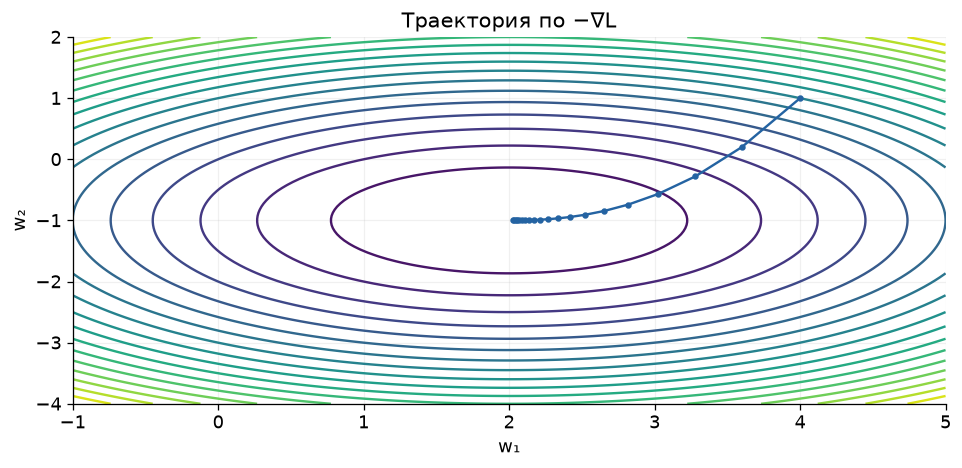

backward применяет цепное правило к вычислительному графу. Градиенты накапливаются в .grad; перед новым шагом их обнуляют. Отрицательный градиент задаёт локальное направление уменьшения функции.

In [3]:
w = torch.tensor(10.0, requires_grad=True)
loss = (w - 3) ** 2
loss.backward()
g1 = w.grad.item()
((w - 3) ** 2).backward()
print("Накопление:", g1, "→", w.grad.item())
assert w.grad.item() == 2 * g1
w.grad.zero_()
track = []
for _ in range(30):
    loss = (w - 3) ** 2
    loss.backward()
    with torch.no_grad():
        w -= 0.1 * w.grad
    w.grad.zero_()
    track.append(w.item())
print("Autograd, итоговый w:", w.item())
a, b = np.meshgrid(np.linspace(-1, 5, 120), np.linspace(-4, 2, 120))
plt.contour(a, b, (a - 2) ** 2 + 2 * (b + 1) ** 2, levels=20)
point = np.array([4.0, 1.0])
path = []
for _ in range(20):
    path.append(point.copy())
    point -= 0.1 * np.array([2 * (point[0] - 2), 4 * (point[1] + 1)])
path = np.array(path)
plt.plot(path[:, 0], path[:, 1], "o-", markersize=3)
plt.xlabel("w₁")
plt.ylabel("w₂")
plt.title("Траектория по −∇L")
showfig("gradient_geometry", OUT)
note(
    "backward применяет цепное правило к вычислительному графу. Градиенты накапливаются в .grad; перед новым шагом их обнуляют. Отрицательный градиент задаёт локальное направление уменьшения функции."
)

## Задания 12–20. От линейной модели к MLP

Сначала y = 2x + 1 вручную и через nn.Linear, затем x², цепное правило и подсчёт параметров.

Ручная линейная модель: 1.9999996423721313 0.9999997019767761


nn.Linear: [[1.9999974]] [0.99992615]


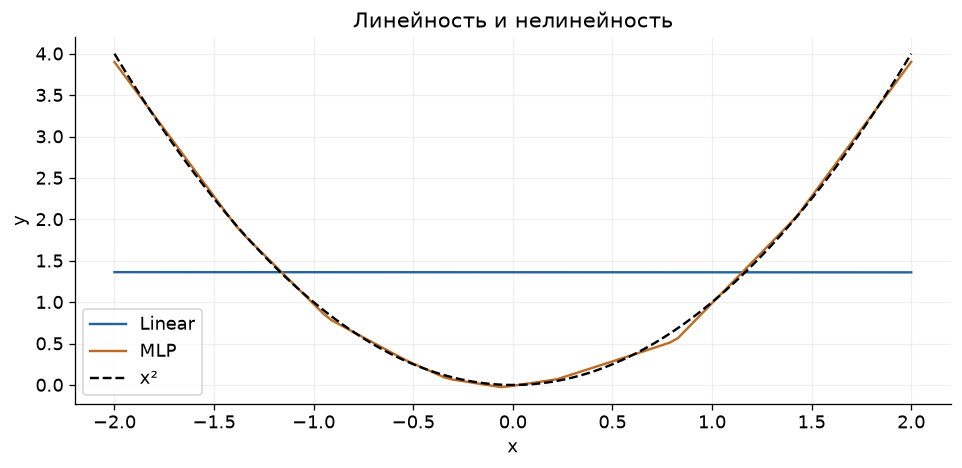

,model,MSE
0,Linear,1.47982
1,MLP,0.00140


Цепное правило dL/dw1: 24.0 аналитически: 24
[('net.0.weight', (16, 1), 16), ('net.0.bias', (16,), 16), ('net.2.weight', (1, 16), 16), ('net.2.bias', (1,), 1)]
Параметров: 49 вручную: 49


Линейная модель восстанавливает аффинную зависимость. Для x² требуется нелинейная композиция. Первый слой 1→16 содержит 32 параметра, второй 16→1 — 17, всего 49.

In [4]:
seed_all()
x = torch.linspace(-2, 2, 100)[:, None]
y = 2 * x + 1
w = torch.zeros(1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
for _ in range(180):
    l = ((x * w + b - y) ** 2).mean()
    l.backward()
    with torch.no_grad():
        w -= 0.05 * w.grad
        b -= 0.05 * b.grad
    w.grad.zero_()
    b.grad.zero_()
print("Ручная линейная модель:", w.item(), b.item())
lin = nn.Linear(1, 1)
lin, h, _ = fit(
    lin, (x, y), (x, y), epochs=150, lr=0.05, optimizer="SGD", task="regression"
)
print("nn.Linear:", lin.weight.detach().numpy(), lin.bias.detach().numpy())
curves = {}
regrows = []
for label, model in [
    ("Linear", nn.Linear(1, 1)),
    ("MLP", MLP(1, 1, (16,), activation="relu")),
]:
    model, h, _ = fit(
        model, (x, x * x), (x, x * x), epochs=400, lr=0.01, task="regression"
    )
    curves[label] = h
    with torch.no_grad():
        pred = model(x).numpy()
    plt.plot(x.numpy(), pred, label=label)
    regrows.append({"model": label, "MSE": mean_squared_error((x * x).numpy(), pred)})
plt.plot(x.numpy(), (x * x).numpy(), "k--", label="x²")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("Линейность и нелинейность")
showfig("linear_vs_mlp", OUT)
table(regrows, OUT, "nonlinearity")
x0 = torch.tensor(2.0)
w1 = torch.tensor(1.0, requires_grad=True)
w2 = torch.tensor(3.0, requires_grad=True)
a = torch.relu(w1 * x0)
yh = w2 * a
L = (yh - 4) ** 2
L.backward()
print("Цепное правило dL/dw1:", w1.grad.item(), "аналитически:", 2 * (6 - 4) * 3 * 2)
net = MLP(1, 1, (16,))
print([(n, tuple(p.shape), p.numel()) for n, p in net.named_parameters()])
print("Параметров:", count_params(net), "вручную:", 1 * 16 + 16 + 16 * 1 + 1)
note(
    "Линейная модель восстанавливает аффинную зависимость. Для x² требуется нелинейная композиция. Первый слой 1→16 содержит 32 параметра, второй 16→1 — 17, всего 49."
)

## Общее мини-исследование. Три запуска

Меняю learning rate при одинаковых данных и начальных весах.

In [5]:
rows = []
for lr in [0.001, 0.01, 0.05]:
    seed_all()
    m = MLP(1, 1, (16,), activation="tanh")
    m, h, t = fit(m, (x, x * x), (x, x * x), epochs=200, lr=lr, task="regression")
    rows.append({"lr": lr, "final_loss": h.iloc[-1].val_loss, "seconds": t})
table(rows, OUT, "common_three_experiments");

,lr,final_loss,seconds
0,0.001,1.15378,0.09890
1,0.010,0.00563,0.09753
2,0.050,0.00161,0.09234


## Вариант 11. Размер обучающей выборки

Зависимость y = x·sin(x), x ∈ [−10, 10]. Сеть 1→64→64→1, Tanh, Adam, 700 эпох. Сравниваю вложенные выборки из 20, 50, 100, 500 и 1000 точек на общей сетке без шума.

Сохраняю веса с минимальной train MSE. Значения train_MSE и grid_MSE относятся к этим весам; last_epoch_train_MSE — к последней эпохе.

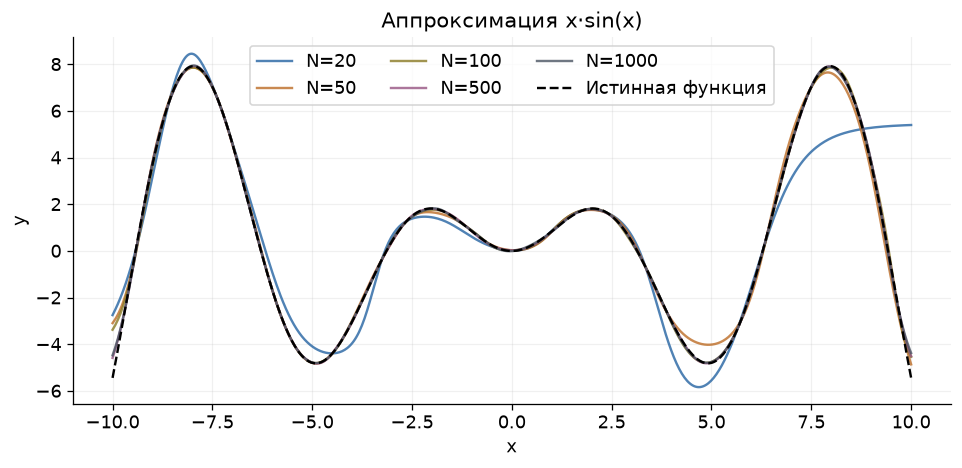

,N,train_MSE,last_epoch_train_MSE,grid_MSE,seconds
0,20,0.17644,0.18067,3.17219,0.25640
1,50,0.02159,0.13566,0.08777,0.34689
2,100,0.00689,0.20518,0.03535,0.38893
3,500,0.00476,0.00487,0.00879,0.89556
4,1000,0.00633,0.06478,0.01190,1.82925


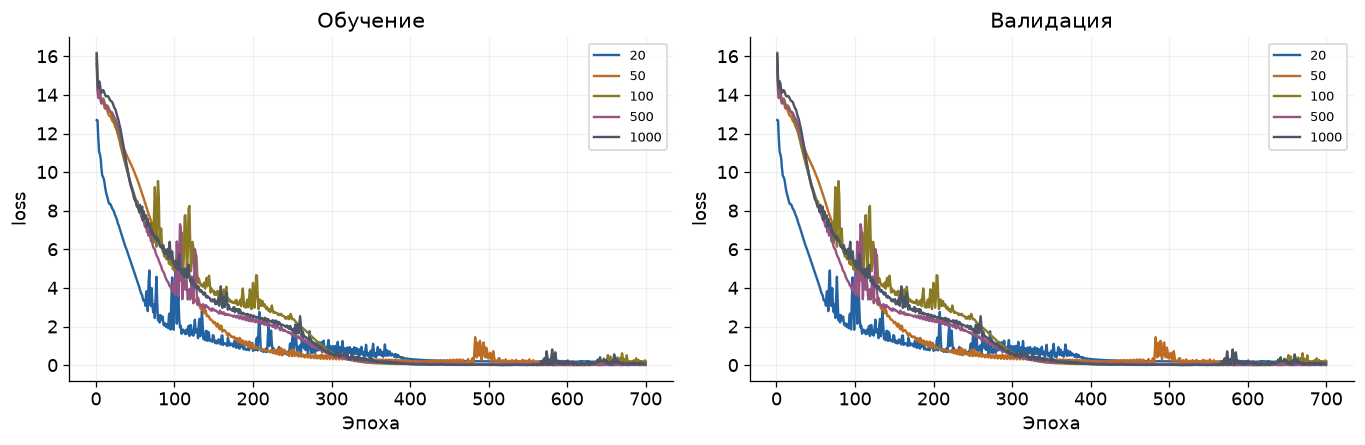

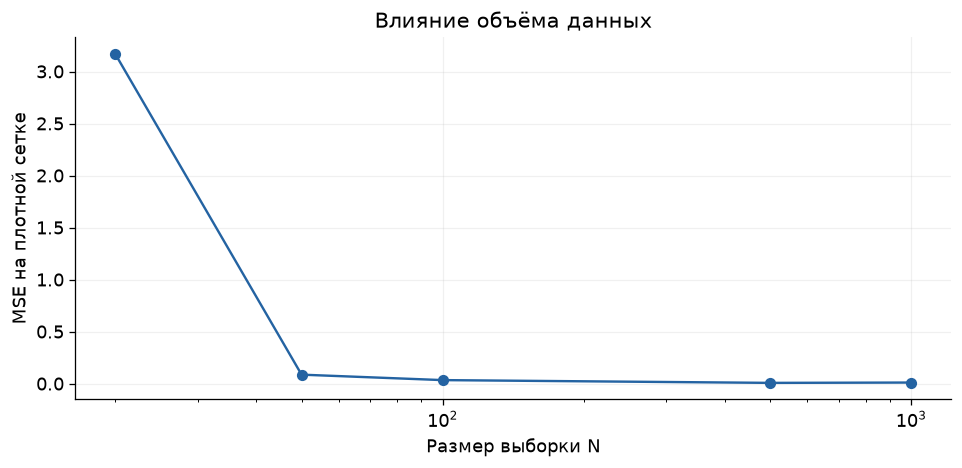

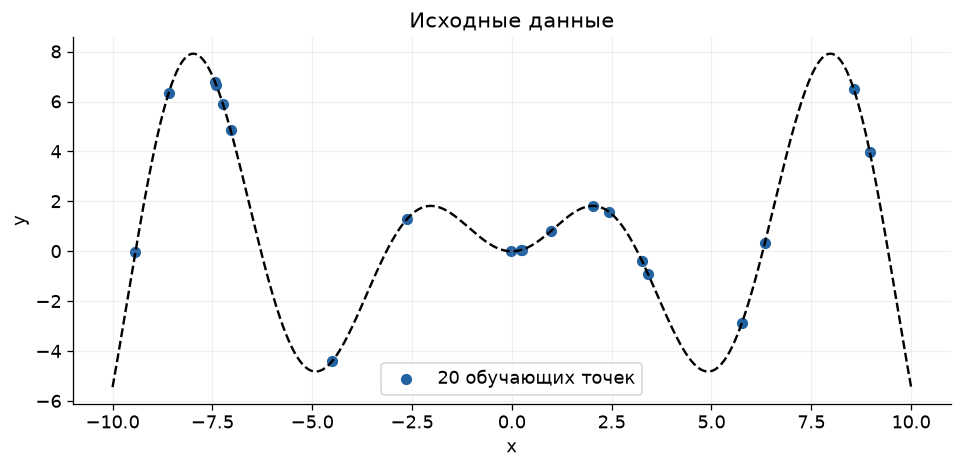

Лучший результат данного сравнения: N=500, MSE=0.00879. При фиксированном бюджете оптимизации качество зависит и от покрытия интервала, и от сходимости; монотонность по N не гарантируется.

In [6]:
seed_all()
pool = np.random.default_rng(11).uniform(-10, 10, 1000).astype("float32")[:, None]
grid = tensor(np.linspace(-10, 10, 600, dtype="float32")[:, None])
truth = grid * torch.sin(grid)
rows = []
curves = {}
models = {}
for n in [20, 50, 100, 500, 1000]:
    xx = tensor(pool[:n])
    yy = xx * torch.sin(xx)
    seed_all()
    m = MLP(1, 1, (64, 64), activation="tanh")

    m, h, t = fit(
        m, (xx, yy), (xx, yy), epochs=700, batch=1000, lr=0.01, task="regression"
    )
    models[n] = m
    curves[str(n)] = h
    with torch.no_grad():
        p = m(grid).numpy()
    rows.append(
        {
            "N": n,
            "train_MSE": float(((m(xx) - yy) ** 2).mean().detach()),
            "last_epoch_train_MSE": h.iloc[-1].train_loss,
            "grid_MSE": mean_squared_error(truth.numpy(), p),
            "seconds": t,
        }
    )
    plt.plot(grid.numpy(), p, label=f"N={n}", alpha=0.8)
plt.plot(grid.numpy(), truth.numpy(), "k--", label="Истинная функция")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Аппроксимация x·sin(x)")
plt.legend(ncol=3)
showfig("sample_size_predictions", OUT)
df = table(rows, OUT, "variant11_sample_size")
histories(curves, OUT, "variant11_learning")
plt.plot(df.N, df.grid_MSE, "o-")
plt.xscale("log")
plt.xlabel("Размер выборки N")
plt.ylabel("MSE на плотной сетке")
plt.title("Влияние объёма данных")
showfig("sample_size_mse", OUT)
plt.scatter(pool[:20], pool[:20] * np.sin(pool[:20]), label="20 обучающих точек")
plt.plot(grid.numpy(), truth.numpy(), "k--")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("Исходные данные")
showfig("training_points", OUT)
best = df.loc[df.grid_MSE.idxmin()]
note(
    f"Лучший результат данного сравнения: N={int(best.N)}, MSE={best.grid_MSE:.5f}. При фиксированном бюджете оптимизации качество зависит и от покрытия интервала, и от сходимости; монотонность по N не гарантируется."
)
torch.save(models[1000].state_dict(), OUT / "best_model.pt")

## Дополнительное исследование. Три learning rate

Для N = 100 сравниваю три шага Adam и считаю норму градиента.

In [7]:
rows = []
for lr in [0.001, 0.003, 0.01]:
    seed_all()
    xx = tensor(pool[:100])
    yy = xx * torch.sin(xx)
    m = MLP(1, 1, (64, 64), activation="tanh")
    m, h, t = fit(
        m, (xx, yy), (xx, yy), epochs=400, batch=1000, lr=lr, task="regression"
    )
    m.zero_grad()
    ((m(xx) - yy) ** 2).mean().backward()
    norm = math.sqrt(sum(float(p.grad.square().sum()) for p in m.parameters()))
    with torch.no_grad():
        score = mean_squared_error(truth.numpy(), m(grid).numpy())
    rows.append({"lr": lr, "grid_MSE": score, "gradient_norm": norm})
table(rows, OUT, "additional_three_experiments")
note(
    "Вывод: объём данных влияет на восстановление колебаний между обучающими точками. Сеть аппроксимирует зависимость в пределах заданного интервала. Низкая train MSE на малой выборке сама по себе не устанавливает качество между точками. Для устойчивого вывода нужны повторные выборки и интервальная оценка."
)

,lr,grid_MSE,gradient_norm
0,0.001,5.47752,1.12235
1,0.003,2.85837,1.94064
2,0.010,0.13631,3.45793


Вывод: объём данных влияет на восстановление колебаний между обучающими точками. Сеть аппроксимирует зависимость в пределах заданного интервала. Низкая train MSE на малой выборке сама по себе не устанавливает качество между точками. Для устойчивого вывода нужны повторные выборки и интервальная оценка.

## Ответы на контрольные вопросы

1. Нейронная сеть — параметризованная композиция функций.

2. Параметры модели — обучаемые веса, смещения и другие изменяемые коэффициенты.

3. Функция потерь измеряет несоответствие предсказаний целевым значениям.

4. Производная показывает локальную чувствительность loss к малому изменению параметра.

5. Градиент объединяет частные производные по всем параметрам.

6. Градиент направлен в сторону наибольшего локального роста функции в евклидовой метрике.

7. Отрицательный градиент задаёт направление локального уменьшения loss при достаточно малом шаге.

8. Learning rate масштабирует обновление параметров.

9. Слишком маленький шаг замедляет приближение к подходящей области параметров.

10. Слишком большой шаг вызывает перескоки, колебания и возможную расходимость.

11. Аналитическая производная получается по правилам дифференцирования; численная оценивается по разностям значений с ошибкой округления и аппроксимации.

12. requires_grad=True включает отслеживание операций для вычисления градиентов по этому тензору.

13. loss.backward() распространяет производные по графу и накапливает их в .grad.

14. zero_grad() удаляет градиенты предыдущего шага.

15. Накопление позволяет суммировать градиенты нескольких loss или microbatch; без очистки оно меняет обычный алгоритм обучения.

16. Вычислительный граф связывает промежуточные тензоры с операциями, которыми они получены.

17. Backpropagation многократно применяет цепное правило к графу в обратном порядке.

18. optimizer.step() изменяет параметры по текущим .grad и состоянию выбранного оптимизатора.

19. Архитектура задаёт семейство функций, обучение выбирает параметры внутри этого семейства.

20. Композиция линейных/аффинных слоёв без нелинейности сводится к одной матрице и смещению.

21. Активация добавляет нелинейность и расширяет класс зависимостей.

22. nn.Linear(1,1) задаёт прямую wx+b, поэтому не может точно представить x² на целом интервале.

23. Композиция нелинейных слоёв строит более сложные преобразования признаков.

24. Обучаемый параметр — тензор, по которому вычисляются градиенты и который включён в оптимизатор.

25. nn.Linear(n,m) с bias содержит m·n весов и m смещений, всего m(n+1).

26. Большая выборка обычно лучше покрывает область входов, но результат зависит также от шума и бюджета обучения.

27. Шум повышает достижимую ошибку наблюдений и может создавать подгонку случайных отклонений.

28. Оптимизаторы используют разные масштабы и историю градиентов, поэтому строят разные траектории.

29. Евклидова норма градиента равна sqrt(суммы квадратов его компонент).

30. Нестабильность проявляется колебаниями/ростом loss, большими градиентами, NaN или Inf; требуется проверка масштаба входов, шага и вычислений.